# Simpsons opt experiment data processing and report

In [2]:
import pathlib
import typing

import numpy as np
import pandas as pd
import spock
import json
import matplotlib.pyplot as plt
import seaborn as sns

import yaml

In [3]:
sns.set_theme()
plt.rcParams['figure.figsize'] = (10.0, 8.0)

In [4]:
PATH_EXPERIMENT = "/beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW"
SEED_ATTRS = ["augmentation_seed", "train_test_split_algorithm_seed"]

## Read the data

In [5]:
class ExperimentResult(typing.NamedTuple):
    config: dict[str, typing.Any]
    result: dict[str, typing.Any]

def read_opt_results(path_experiment: pathlib.Path) -> dict[str, ExperimentResult]:
    path_results = path_experiment / "results"
    d = {}
    for path_result in path_results.glob("*"):
        path_spock_config = next(path_result.glob("*.spock.cfg.yaml"))
        uid = path_result.stem
        with open(path_spock_config, "r") as config_file:
            config = yaml.load(config_file)
        try:
            result = json.loads(next(path_result.glob("result-*.json")).read_text())
        except StopIteration:
            print("Error in train, results do not exist for: ", path_result)
            continue
        d[uid] = ExperimentResult(config=config["ExperimentConfig"], result=result)
    return d

In [6]:
opt_results = read_opt_results(pathlib.Path(PATH_EXPERIMENT))
print("Observations count", len(opt_results.values()))

/tmp/ipykernel_1396082/3090002764.py:12: YAMLLoadWarning: calling yaml.load() without Loader=... is deprecated, as the default Loader is unsafe. Please read https://msg.pyyaml.org/load for full details.
  config = yaml.load(config_file)


Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/results/52f2bbc5-c4ff-4318-8203-514f468003d1
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/results/d169c60c-3930-4358-95c6-5fd84d393672
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/results/db057f99-ce7a-4688-a0e6-561035a051c1
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/results/d7742414-6f94-45aa-9cce-d4a6ca64cc89
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/results/5cb83137-088e-4845-aff8-d5359529db36
Error in train, results do not exist for:  /beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/results/e79f9

## Process the data

In [7]:
def get_metric_values(
        opt_results: dict[str, ExperimentResult],
) -> pd.DataFrame:
    seeds = []
    metric_values = []
    for experiment_uid, opt_result in opt_results.items():
        seeds.append((
            opt_result.config["train_test_split_algorithm_seed"],
            opt_result.config["augmentation_seed"]
        ))
        metric_values.append(opt_result.result["result_data"]["target_metric_value"])
    index = pd.MultiIndex.from_tuples(seeds, names=["train_test_split_algorithm_seed", "augmentation_seed"])
    s = pd.DataFrame(data=metric_values, index=index, columns=[opt_result.config["target_metric"]])
    return s

In [8]:
PATH_DATA_PROCESSED = pathlib.Path(PATH_EXPERIMENT) / "data" / "processed"
PATH_DATA_PROCESSED.mkdir(parents=True, exist_ok=True)
PATH_DATA_PROCESSED

PosixPath('/beegfs/ws/0/s4610340-isml/simpsons/experiments/20_simpsons_opt_split_augment_AdamW/data/processed')

In [9]:
PATH_METRIC_VALUES = PATH_DATA_PROCESSED / "metric_values.csv"
if PATH_METRIC_VALUES.exists():
    metric_values = pd.read_csv(PATH_METRIC_VALUES, index_col=[0, 1])
else:
    metric_values = get_metric_values(opt_results)
    metric_values.to_csv(PATH_METRIC_VALUES, index=True)

metric_values

error_rate
train_test_split_algorithm_seed augmentation_seed            
839                             5982                 0.154030
                                2199                 0.147463
262                             9394                 0.151343
376                             854                  0.132239
431                             9620                 0.133134
...                                                       ...
843                             1736                 0.159701
601                             6691                 0.136418
262                             3752                 0.160000
843                             4560                 0.140299
449                             4222                 0.128955

[9964 rows x 1 columns]

<Axes: >

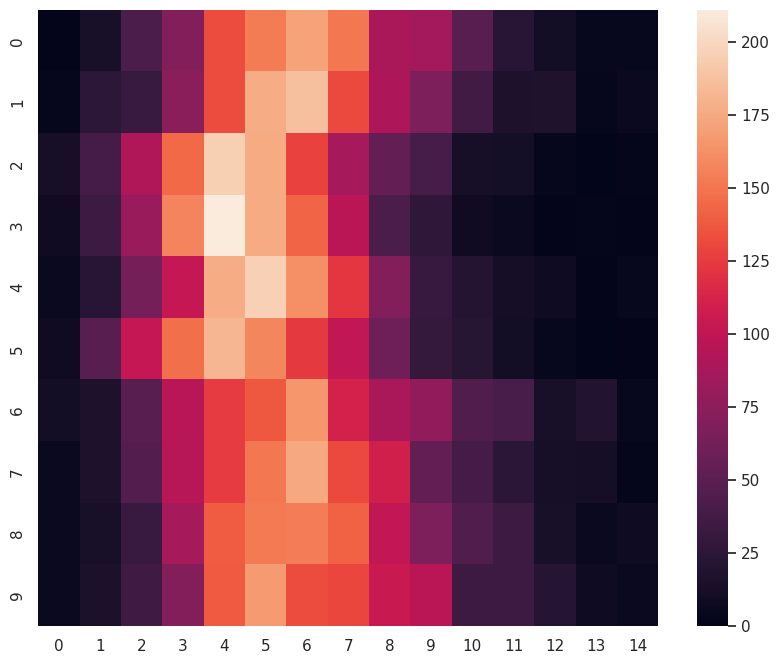

In [10]:
matrix = []
for seed_split, df_seed_split in metric_values.groupby("train_test_split_algorithm_seed"):
    heights, edges = np.histogram(df_seed_split["error_rate"], bins=15)
    matrix.append(heights)

sns.heatmap(matrix, cmap="rocket")


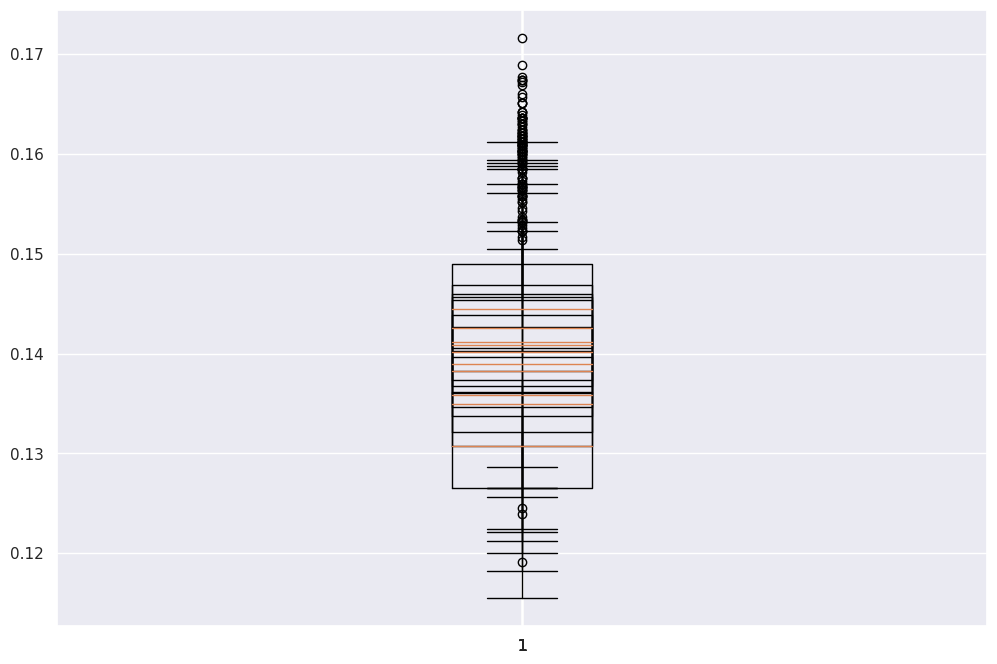

In [11]:
ax: plt.Axes
fig: plt.Figure
fig, ax = plt.subplots(figsize=(12, 8))

for seed_split, df_seed_split in metric_values.groupby("train_test_split_algorithm_seed"):
    ax.boxplot(df_seed_split["error_rate"])

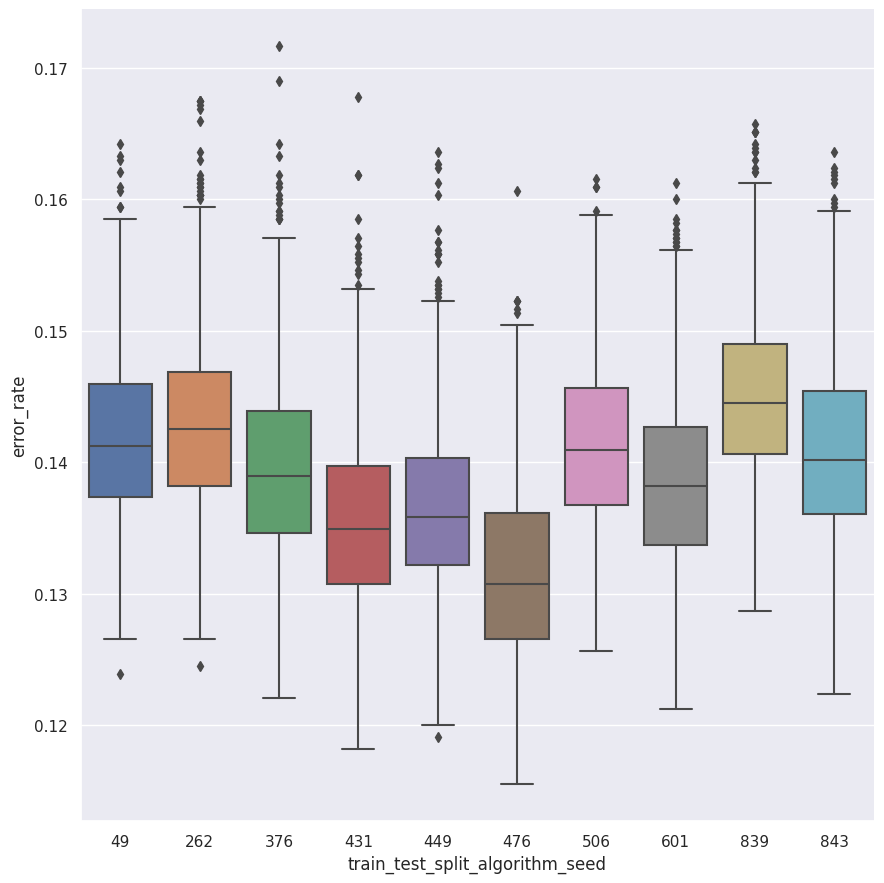

In [12]:
sns.catplot(data=metric_values.reset_index(), x="train_test_split_algorithm_seed", y="error_rate", kind="box", height=9)

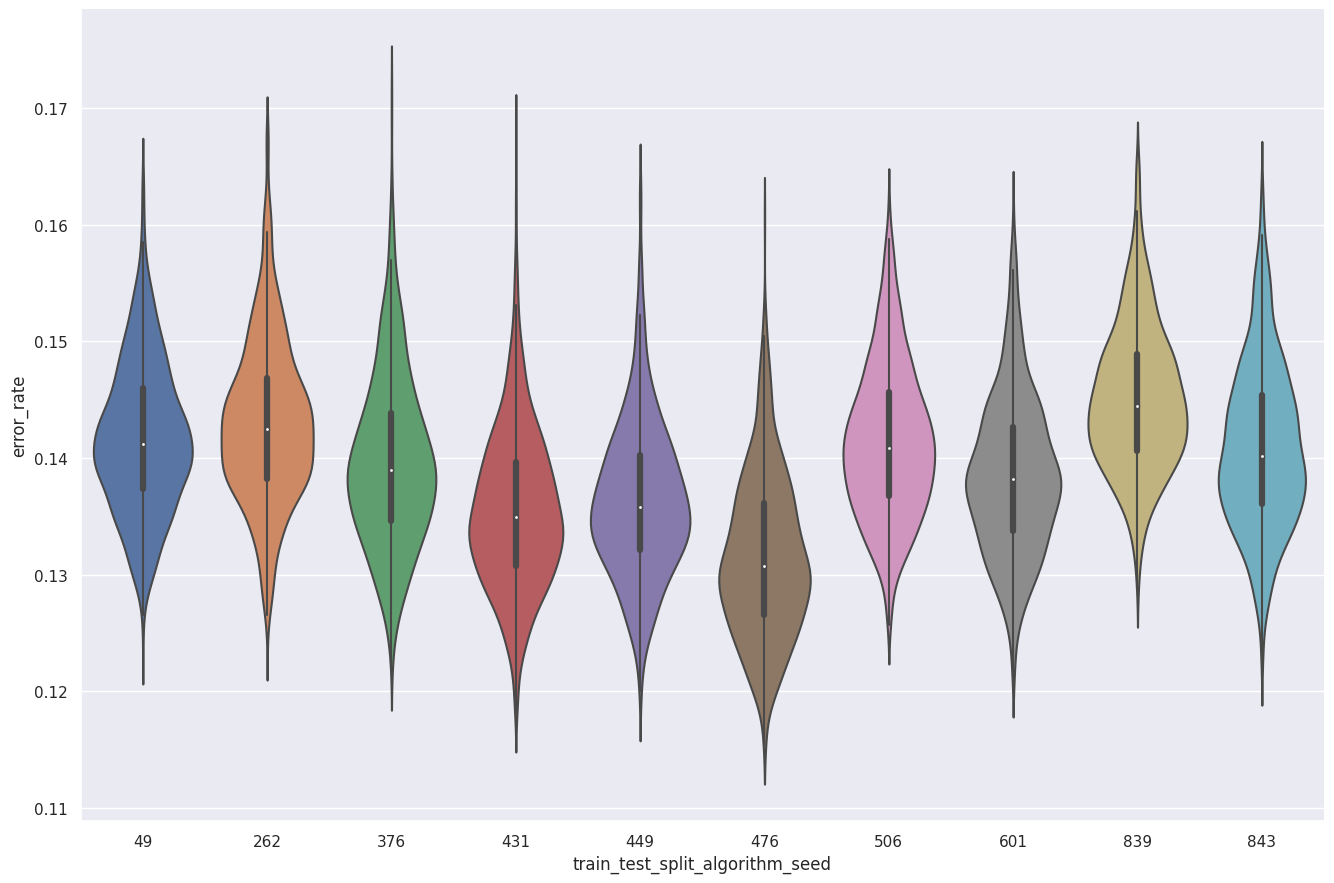

In [13]:
sns.catplot(data=metric_values.reset_index(), x="train_test_split_algorithm_seed", y="error_rate", kind="violin", height=9, aspect=1.5)